# Srivastava–Yeh: homogeneous-soil infiltration and outflow

The reference is [Srivastava and Yeh (1991)](https://doi.org/10.1029/90WR02772), **Example 1: Homogeneous Soil**, pp. 758–760. The column is 100 cm thick, saturated conductivity $K_{\mathrm{s}}$ is 1 cm/h, and the lower pressure head is fixed at zero. Wetting changes the surface rate from 0.1 to 0.9 cm/h; drainage reverses that change.

These are fixed-water-table flow checks. We use `profile_at_time` and `basal_flux_at_time`, so the storage-based moving-water-table and slope-stability calculations are not applied. The case therefore tests the analytical infiltration component, not the full landslide model. The ground-surface slope angle is $\delta=0$. A separate inclined-column diagnostic is needed to distinguish the pressure conversions.

The plots use the paper's upward coordinate: height above the water table is `100*(1-z)` cm, where the package's depth $z$ increases downward from the surface. Public evaluation times are in hours; hydraulic properties and computed fluxes use SI units. Plots convert pressure to centimetres and flux to cm/h. The independent reference solver uses seconds, with an explicit conversion at its call. The model starts from the previous steady rate at $t=0$, where $t$ is elapsed time; the new surface rate stays active for the entire plotted interval.


## Soil parameters

Here $\alpha$ is the intrinsic Gardner parameter; $\theta_{\mathrm{s}}$ and $\theta_{\mathrm{r}}$ are saturated and residual volumetric water contents. See [Gardner laws](/unsatstab/fundamentals/#gardner-constitutive-laws-and-parameters).

| Soil | $\alpha$ [cm⁻¹] | $\alpha$ [m⁻¹] | $\theta_{\mathrm{s}}$ [m³/m³] | $\theta_{\mathrm{r}}$ [m³/m³] |
| --- | ---: | ---: | ---: | ---: |
| Figures 1–2 / solid outflow in Figure 5 | 0.01 | 1 | 0.45 | 0.20 |
| Figures 3–4 / dashed outflow in Figure 5 | 0.1 | 10 | 0.40 | 0.06 |

The comparisons follow the article: Figures 1–2 for the first soil, Figures 3–4 for the second soil, and Figure 5 for wetting outflow from both soils. Each computed figure is followed by the supplied reference image in the same panel order. Reference-image code is collapsed in JupyterLab and hidden in the documentation.


In [1]:
%matplotlib inline
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import tol_colors as tc
from IPython.display import display, Image, Markdown
import unsatstab as us
from unsatstab.analytical import (
    profile_at_time, basal_flux_at_time, pressure_from_conductivity,
    water_content_from_pressure,
)
from unsatstab.roots import compute_roots

REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/unsatstab").is_dir())
ASSETS = REPO / "docs/assets"
mpl.rcParams.update({
    "font.family": "DejaVu Serif",
    "font.serif": ["DejaVu Serif"],
    "font.size": 8.5,
    "mathtext.fontset": "dejavuserif",
    "axes.titlesize": 9,
    "axes.labelsize": 8.5,
    "axes.linewidth": 1.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.unicode_minus": False,
    "axes.grid": False,
    "xtick.labelsize": 7.5,
    "ytick.labelsize": 7.5,
    "legend.fontsize": 7.5,
    "legend.frameon": False,
    "xtick.major.width": 1.5,
    "ytick.major.width": 1.5,
})
TIME_CMAP = tc.colormaps["rainbow_PuBr"]
KS = 0.01 / 3600.  # 1 cm/h expressed in m/s
SOILS = {1.: (0.45, 0.20), 10.: (0.40, 0.06)}  # alpha in m^-1

In [2]:
def calculate(alpha, scenario, hours):
    theta_s, theta_r = SOILS[alpha]
    initial, applied = (0.1, 0.9) if scenario == "wetting" else (0.9, 0.1)
    hydro = us.HydraulicProperties(
        slope_angle_deg=0., maximum_depth=1., initial_water_table_depth=1.,
        saturated_hydraulic_conductivity=KS, alpha=alpha,
        theta_s=theta_s, theta_r=theta_r, long_term_infiltration=initial*KS,
        n_roots=500, n_depths=200, equation_set="srivastava_yeh",
    )
    # Keep the new rate active beyond the last plotted time. This is a
    # sustained rate change, not a rain pulse ending at t=100 h.
    forcing = us.RainfallSeries.constant(
        applied * KS * 3.6e6,  # convert the applied rate from m/s to mm/h
        101.0,  # duration in hours
    )
    roots = compute_roots(hydro.transformed_alpha, 1., hydro.n_roots)
    profiles = [profile_at_time(t, hydro, forcing, roots=roots) for t in hours]
    outflow_hours = np.linspace(0.,100.,401)
    outflow = np.array([basal_flux_at_time(t,hydro,forcing,roots=roots)
                       for t in outflow_hours])
    return dict(alpha=alpha, scenario=scenario, hydro=hydro, forcing=forcing,
                roots=roots, hours=np.array(hours), profiles=profiles,
                outflow_hours=outflow_hours, outflow=outflow,
                initial=initial, applied=applied)


def verify(case):
    numerical = solve_reference(
        case["alpha"],case["hydro"].theta_s,case["hydro"].theta_r,
        case["initial"]*KS,case["applied"]*KS,case["hours"]*3600.,  # convert hours to seconds
    )
    pressure_errors, moisture_errors, flux_errors = [], [], []
    for i,p in enumerate(case["profiles"]):
        pressure_errors.append(np.max(np.abs(p["pressure_head"]-np.interp(
            p["z"],numerical["z"],numerical["pressure_head"][i]))))
        moisture_errors.append(np.max(np.abs(p["volumetric_water_content"]-np.interp(
            p["z"],numerical["z"],numerical["volumetric_water_content"][i]))))
        flux = basal_flux_at_time(case["hours"][i],case["hydro"],
                                  case["forcing"],roots=case["roots"])
        flux_errors.append(abs(flux-numerical["basal_flux"][i]))
    assert max(pressure_errors) < 0.001  # 0.1 cm
    assert max(moisture_errors) < 0.0001
    assert max(flux_errors) / KS < 0.001
    return {"alpha [cm^-1]":case["alpha"]/100., "scenario":case["scenario"],  # convert m⁻¹ to cm⁻¹
            "maximum pressure difference [cm]":max(pressure_errors)*100.,  # convert m to cm
            "maximum moisture difference [m³/m³]":max(moisture_errors),
            "maximum flux difference [cm/h]":max(flux_errors)*3600.*100.}  # convert m/s to cm/h


def profile_panel(ax,case,field,scale,title):
    # scale=100 converts pressure head from m to cm; scale=1 keeps water content unchanged.
    colors=TIME_CMAP(np.linspace(0.05, 0.95, len(case["hours"])))
    for t,p,color in zip(case["hours"],case["profiles"],colors):
        ax.plot(p[field]*scale,(1.-p["z"])*100.,color=color,lw=1.5,label=f"{t:g}")  # convert m to cm
    ax.set(ylim=(0,100),title=title)
    ax.grid(False)
    return ax.get_legend_handles_labels()


def compare_soil(wet, dry):
    fig, axes = plt.subplots(1, 3, figsize=(7.5, 3.5), layout="constrained")
    lower = -100 if wet["alpha"] == 1 else -30
    for ax, case, field, scale, title, xlabel in [
        (axes[0], wet, "pressure_head", 100., "Computed wetting pressure", "Pressure head [cm]"),
        (axes[1], wet, "volumetric_water_content", 1., "Computed wetting water content", "Volumetric water content [m³/m³]"),
        (axes[2], dry, "pressure_head", 100., "Computed drainage pressure", "Pressure head [cm]"),
    ]:
        profile_panel(ax, case, field, scale, title)
        ax.set_xlabel(xlabel)
        if field == "pressure_head":
            ax.set_xlim(lower, 0)
            ax.legend(title="Time [h]", fontsize=7, ncol=2, loc="lower left")
        else:
            ax.set_xlim((.2, .5) if wet["alpha"] == 1 else (0, .4))
    axes[0].set_ylabel("Height above fixed water table [cm]")
    plt.show()

## Independent numerical comparison

In addition to the raster panels, we compare against a separately implemented finite-difference solution of the linear conductivity equation. It uses 800 depth intervals, a maximum time step of 30 s, Crank–Nicolson integration, and two backward-Euler startup half steps to handle the sudden surface-flux change. It does not call the package's roots, response series, or constitutive conversion functions.

The displayed differences are between two numerical implementations. They are not errors measured against digitized published curves. The raster comparison remains qualitative because the paper does not provide machine-readable profiles. The assertions set numerical-comparison tolerances; they do not imply exact agreement or field validation.


The complete reference solver is defined in the next cell. It uses only NumPy and SciPy, with input times and numerical time steps in seconds, lengths in metres and fluxes in m/s. It does not call `unsatstab`; the later comparisons use it as a separate numerical implementation.

In [3]:
import numpy as np
from scipy.sparse import diags
from scipy.sparse.linalg import splu


def solve_reference(alpha, theta_s, theta_r, initial_rate, applied_rate,
                    times_s, *, ks=.01/3600., depth=1., n_intervals=800, step_s=30.):
    times_s = np.asarray(times_s, dtype=float)
    if times_s[0] != 0 or np.any(np.diff(times_s) <= 0):
        raise ValueError('Reference times must start at zero and increase.')
    z = np.linspace(0., depth, n_intervals+1)
    dx = depth/n_intervals
    diffusivity = ks/(alpha*(theta_s-theta_r))
    velocity = ks/(theta_s-theta_r)
    lower = np.full(n_intervals-1, diffusivity/dx**2+velocity/(2*dx))
    upper = np.full(n_intervals-1, diffusivity/dx**2-velocity/(2*dx))
    main = np.full(n_intervals, -2*diffusivity/dx**2)
    # Ghost point enforces K-K_z/alpha = applied_rate at the surface.
    main[0] -= 2*diffusivity*alpha/dx+velocity*alpha
    upper[0] = 2*diffusivity/dx**2
    operator = diags([lower,main,upper],[-1,0,1],format='csc')
    identity = diags(np.ones(n_intervals),format='csc')
    forcing = np.zeros(n_intervals)
    forcing[0] = (2*diffusivity*alpha/dx+velocity*alpha)*applied_rate
    forcing[-1] += (diffusivity/dx**2-velocity/(2*dx))*ks
    current = initial_rate+(ks-initial_rate)*np.exp(-alpha*(depth-z[:-1]))
    conductivity = [np.r_[current,ks]]
    time = 0.
    factors = {}
    startup_steps = 2
    for target in times_s[1:]:
        while time < target-1e-8:
            # Two backward-Euler half steps damp the discontinuous change
            # in surface flux before starting second-order Crank-Nicolson.
            dt = min(step_s/2 if startup_steps else step_s,target-time)
            weight = 1. if startup_steps else .5
            key = (weight,round(dt,8))
            if key not in factors:
                factors[key] = (splu(identity-weight*dt*operator),identity+(1-weight)*dt*operator)
            factor,right = factors[key]
            current = factor.solve(right@current+dt*forcing)
            time += dt
            startup_steps = max(startup_steps-1,0)
        conductivity.append(np.r_[current,ks])
    conductivity = np.array(conductivity)
    pressure = np.log(conductivity/ks)/alpha
    moisture = theta_r+(theta_s-theta_r)*conductivity/ks
    base_gradient = (3*conductivity[:,-1]-4*conductivity[:,-2]+conductivity[:,-3])/(2*dx)
    basal_flux = ks-base_gradient/alpha
    return dict(z=z,conductivity=conductivity,pressure_head=pressure,
                volumetric_water_content=moisture,basal_flux=basal_flux)


## First soil: Figures 1 and 2

The intrinsic Gardner parameter is $\alpha=0.01$ cm⁻¹ (1 m⁻¹), with $\theta_{\mathrm{s}}=0.45$ and $\theta_{\mathrm{r}}=0.20$. Figure 1 shows wetting pressure and water content; Figure 2 shows pressure during the reverse rate change. The three computed panels follow that order.

In [4]:
thin = calculate(1., "wetting", [0,1,3,5,8,10,15,20,30,100])
thin_dry = calculate(1., "drainage", [0,1,3,5,8,10,15,20,30,100])
display(pd.DataFrame([verify(thin), verify(thin_dry)]))

,alpha [cm^-1],scenario,maximum pressure difference [cm],maximum moisture difference [m³/m³],maximum flux difference [cm/h]
0,0.01,wetting,0.000095,1.365092e-07,0.000001
1,0.01,drainage,0.000068,1.392168e-07,0.000001


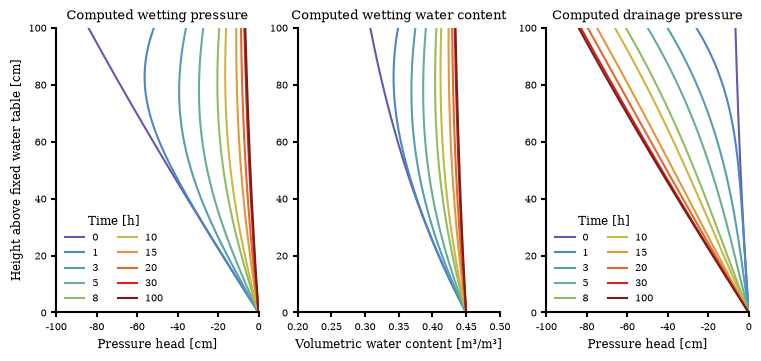

In [5]:
compare_soil(thin, thin_dry)

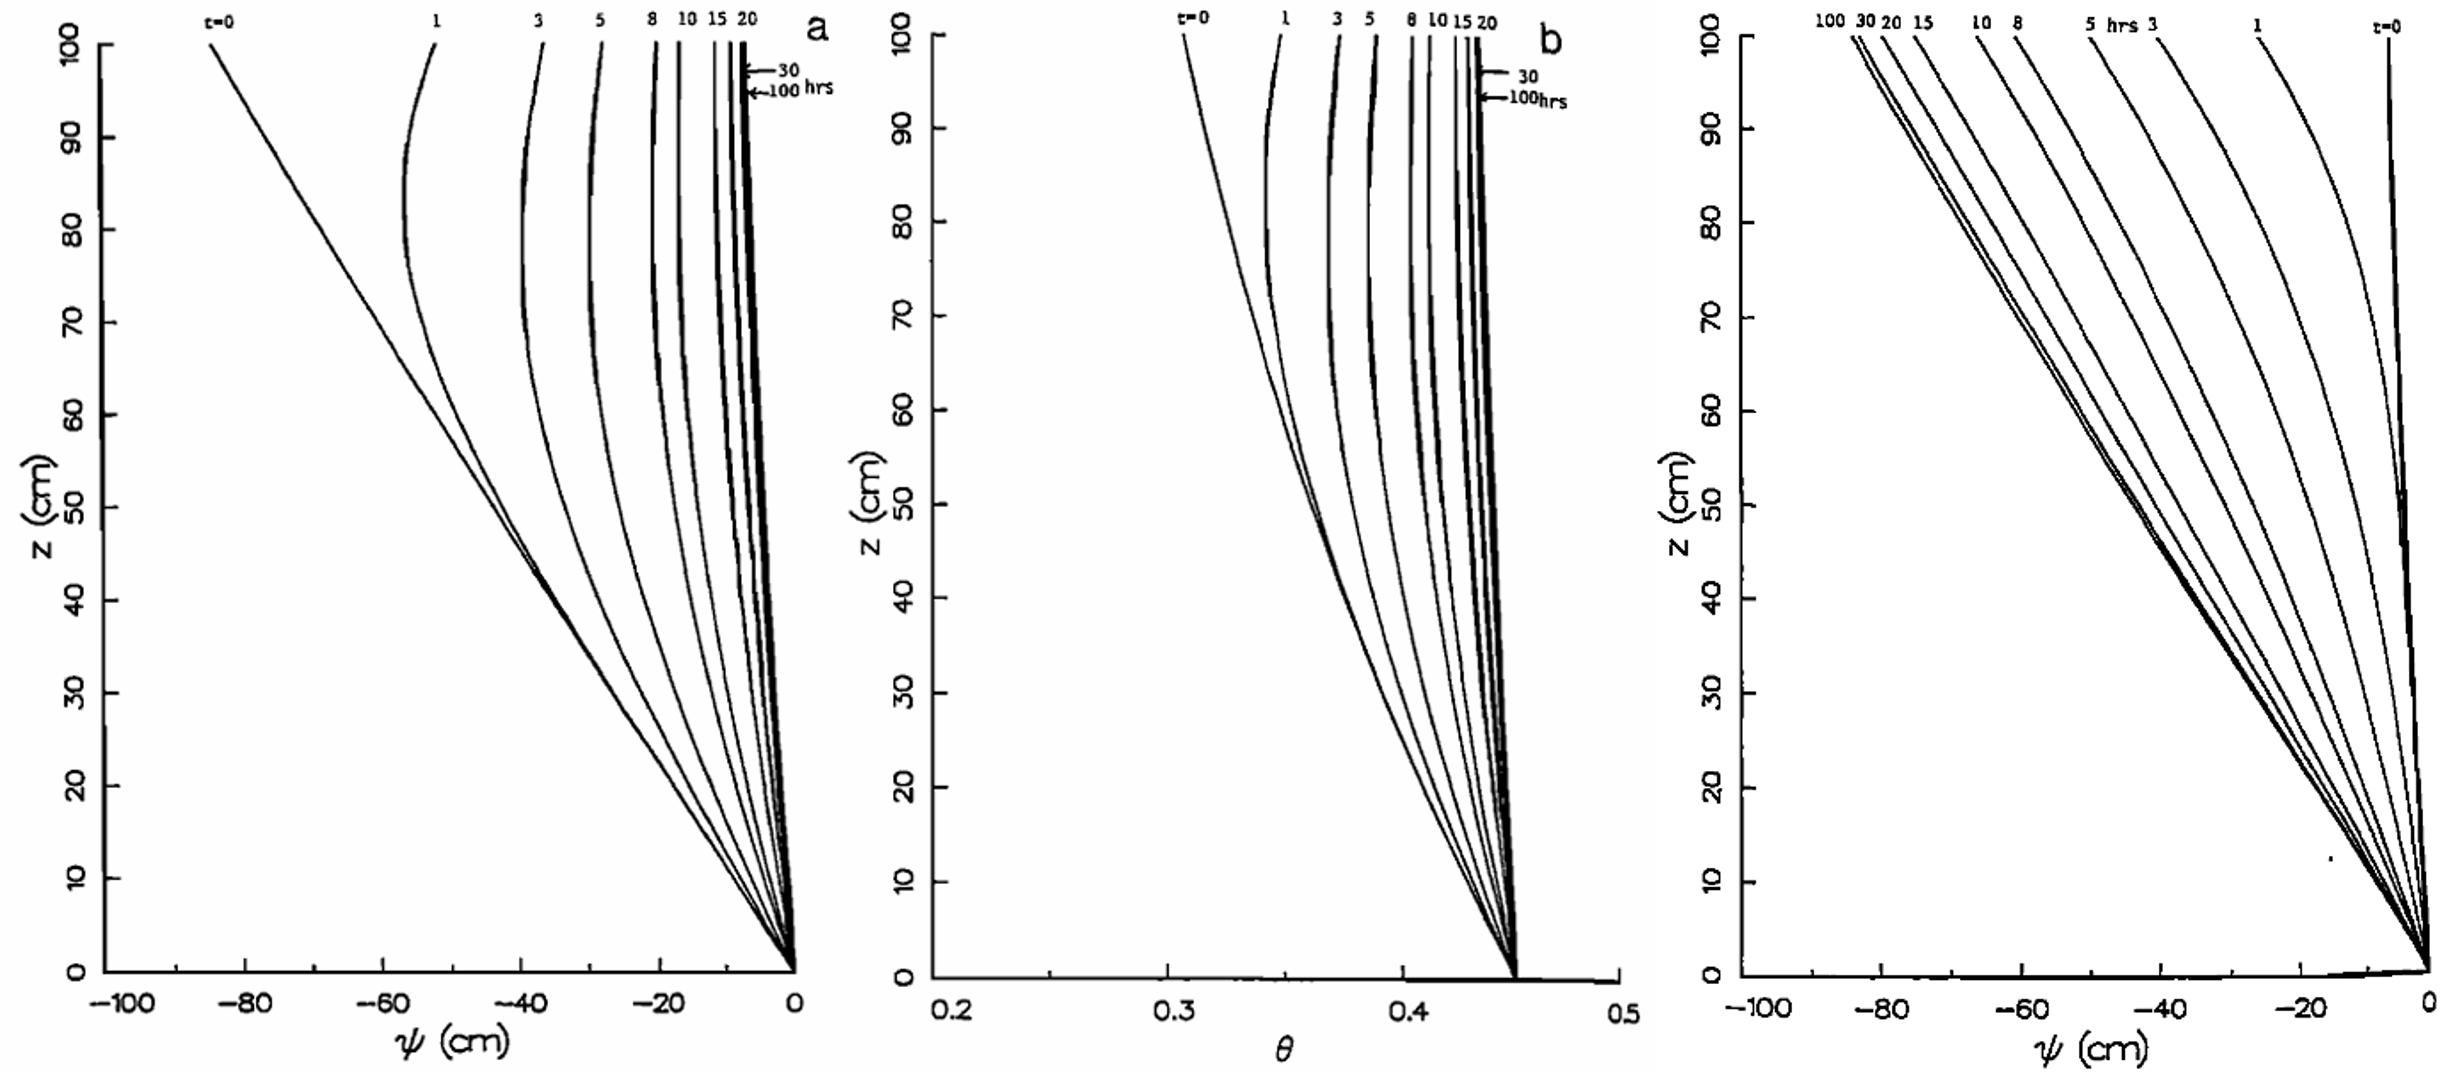

*Published reference: Srivastava and Yeh (1991), Figures 1 and 2: wetting pressure, wetting water content, and drainage pressure for the first soil.*

In [6]:
display(Image(filename=str(ASSETS / "Figures_1_and_2_Srivastava_and_Yeh_1991.png"), width=1200))
display(Markdown('*Published reference: Srivastava and Yeh (1991), Figures 1 and 2: wetting pressure, wetting water content, and drainage pressure for the first soil.*'))

## Second soil: Figures 3 and 4

The intrinsic Gardner parameter is $\alpha=0.1$ cm⁻¹ (10 m⁻¹), with $\theta_{\mathrm{s}}=0.40$ and $\theta_{\mathrm{r}}=0.06$. Figure 3 shows wetting pressure and water content; Figure 4 shows drainage pressure. The larger exponent produces sharper profiles than the first soil.

In [7]:
coarse = calculate(10., "wetting", [0,1,3,5,10,15,20,30,50,75,100])
coarse_dry = calculate(10., "drainage", [0,1,3,5,10,20,30,40,60,100])
display(pd.DataFrame([verify(coarse), verify(coarse_dry)]))

,alpha [cm^-1],scenario,maximum pressure difference [cm],maximum moisture difference [m³/m³],maximum flux difference [cm/h]
0,0.1,wetting,0.000315,0.000001,0.000046
1,0.1,drainage,0.000143,0.000001,0.000035


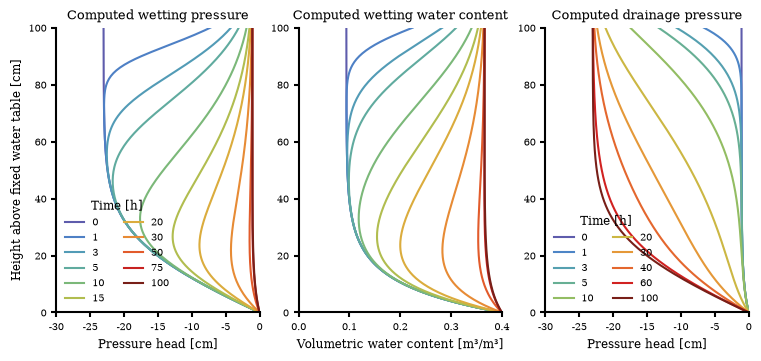

In [8]:
compare_soil(coarse, coarse_dry)

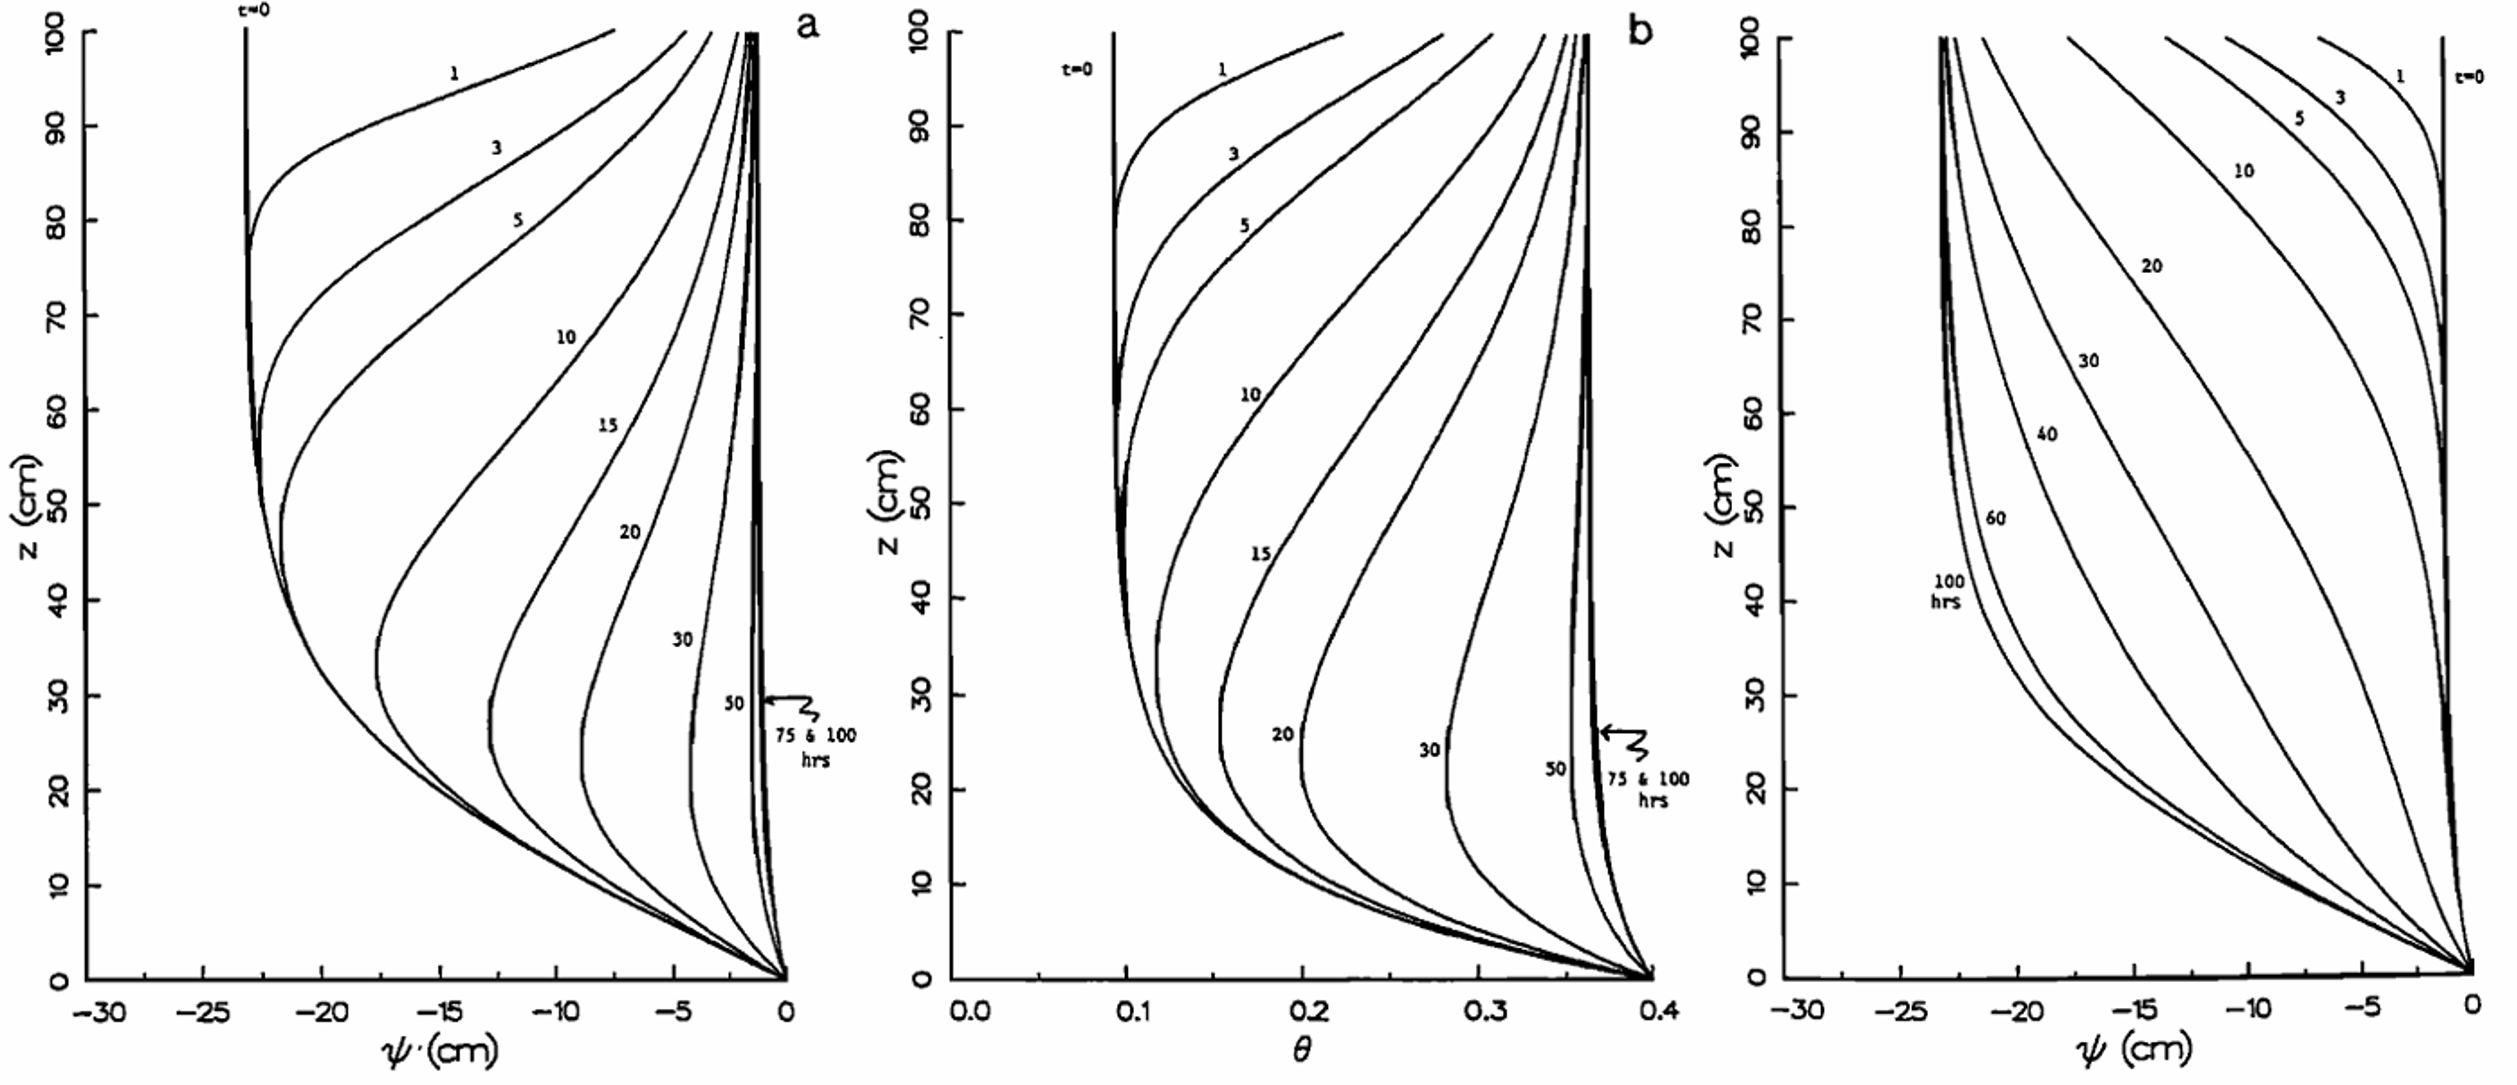

*Published reference: Srivastava and Yeh (1991), Figures 3 and 4: wetting pressure, wetting water content, and drainage pressure for the second soil.*

In [9]:
display(Image(filename=str(ASSETS / "Figures_3_and_4_Srivastava_and_Yeh_1991.png"), width=1200))
display(Markdown('*Published reference: Srivastava and Yeh (1991), Figures 3 and 4: wetting pressure, wetting water content, and drainage pressure for the second soil.*'))

## Both soils: Figure 5

Basal outflow during wetting begins at 0.1 cm/h and approaches the new surface rate of 0.9 cm/h. The solid line represents the first soil and the dashed line the second soil, following Figure 5.

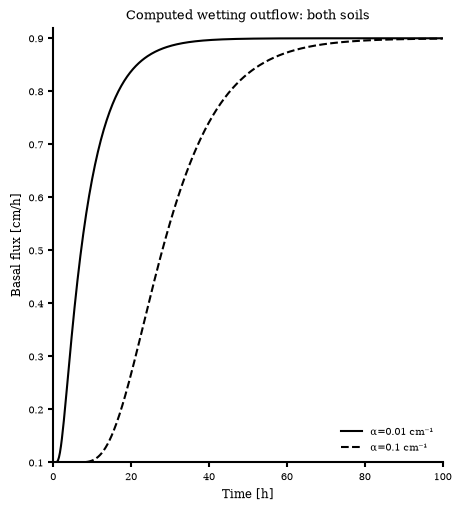

In [10]:
fig, ax = plt.subplots(figsize=(4.5, 5.0), layout="constrained")
for case, style in [(thin, "-"), (coarse, "--")]:
    ax.plot(case["outflow_hours"], case["outflow"] * 3600. * 100., style,
            # Convert basal flux from m/s to cm/h and alpha from m⁻¹ to cm⁻¹.
            label=f"α={case['alpha'] / 100:g} cm⁻¹", color="black")
ax.set(xlabel="Time [h]", ylabel="Basal flux [cm/h]", xlim=(0, 100),
       ylim=(.1, .92), title="Computed wetting outflow: both soils")
ax.legend()
plt.show()

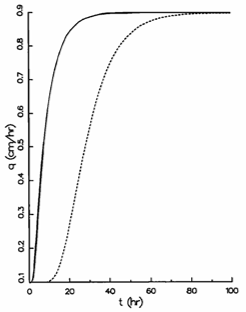

*Published reference: Srivastava and Yeh (1991), Figure 5: basal outflow during wetting for both soils.*

In [11]:
display(Image(filename=str(ASSETS / "Figure_5_Srivastava_and_Yeh_1991.png"), width=450))
display(Markdown('*Published reference: Srivastava and Yeh (1991), Figure 5: basal outflow during wetting for both soils.*'))

## Interpretation and scope

During wetting, pressure becomes less negative and water content increases. During drainage, suction increases. The lower pressure remains zero and the water table stays fixed in all four cases. At long times the profiles approach the steady solution for the imposed rate. The first soil responds earlier than the second soil, as in Figure 5; both the Gardner exponent and the water-content range enter the response scale.

The raster panels support visual comparison of profile shape and response timing. Quantitative differences are measured against the independent finite-difference solver, rather than digitized paper curves. These cases do not apply water-table reconstruction, drainage efficiency, or slope-stability calculations.

## Inclined-column consistency diagnostic

The horizontal example cannot reveal a cosine-factor mismatch: both constitutive sets coincide at δ=0. The diagnostic below instead uses a specified conductivity ratio at 40°. It compares pressure, water content, and the recovered Gardner conductivity ratio. This is a derived consistency check, not a published sloping-soil benchmark. See the [equation comparison](/unsatstab/fundamentals/#pressure-and-water-content-equation-sets).

In [12]:
rows=[]
for equation_set in ["baum_etal","srivastava_yeh"]:
    h=us.HydraulicProperties(slope_angle_deg=40.,maximum_depth=1.,saturated_hydraulic_conductivity=KS,alpha=3.,theta_s=.41,theta_r=.06,equation_set=equation_set)
    psi=pressure_from_conductivity(np.array([.1*KS]),hydro=h)[0]
    theta=water_content_from_pressure(np.array([psi]),hydro=h)[0]
    rows.append({"equation_set":equation_set,"input K/Ks":.1,
                 "pressure head [m]":psi,"water content":theta,
                 "K/Ks recovered using intrinsic Gardner law":np.exp(h.alpha*psi)})
display(pd.DataFrame(rows))

,equation_set,input K/Ks,pressure head [m],water content,K/Ks recovered using intrinsic Gardner law
0,baum_etal,0.1,-1.001937,0.119982,0.049499
1,srivastava_yeh,0.1,-0.767528,0.095000,0.100000
